COU 07506 Digital Signal Processing

WEEK 5 — LAB 2:Implementing the FFT

Name: NASONI JOEL RICHARD

Registration No: 240242468221

Class: BENG24COE

Group: 03

Date: 25/11/2026

Instructor checkpoints signed:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

Task 5.1 — DFT by matrix


In [ ]:
def dft_matrix(N):
    n = np.arange(N)
    return np.exp(-2j*np.pi*np.outer(n, n)/N)

x = np.array([0, 1, 2, 3])
N = 4

X = dft_matrix(N) @ x

print(np.round(X, 4))
print(np.allclose(X, np.fft.fft(x)))

x_back = (dft_matrix(N).conj() @ X) / 4
print(np.round(x_back.real, 6))

[ 6.+0.j -2.+2.j -2.-0.j -2.-2.j]
True
[0. 1. 2. 3.]


Task 5.2 — Bit Reversal

In [ ]:
def bit_reverse_indices(N):
    bits = int(np.log2(N))
    return np.array([
        int(format(i, f"0{bits}b")[::-1], 2)
        for i in range(N)
    ])

print(bit_reverse_indices(8))

[0 4 2 6 1 5 3 7]


Task 5.3 — Iterative Radix-2 FFT

In [ ]:
def fft_iterative(x):
    x = np.asarray(x, dtype=complex)
    N = len(x)

    X = x[bit_reverse_indices(N)].copy()
    size = 2

    while size <= N:
        half = size // 2
        W = np.exp(-2j*np.pi*np.arange(half)/size)

        for start in range(0, N, size):
            top = X[start:start+half].copy()
            bot = X[start+half:start+size] * W

            X[start:start+half] = top + bot
            X[start+half:start+size] = top - bot

        print(f"Stage size={size}: {np.round(X, 4)}")
        size *= 2

    return X

In [ ]:
x = np.array([0, 1, 2, 3])

print("FFT iterative:", np.round(fft_iterative(x), 4))
print("NumPy FFT:", np.round(np.fft.fft(x), 4))

Stage size=2: [ 2.+0.j -2.+0.j  4.+0.j -2.+0.j]
Stage size=4: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]
FFT iterative: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]
NumPy FFT: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]


Task 5.4 — How much faster?

Stage size=2: [-1.1854e+00+0.j -3.9843e+00+0.j  1.1950e-01+0.j -1.1319e+00+0.j
  1.9059e+00+0.j  6.5180e-01+0.j  1.5482e+00+0.j  6.7310e-01+0.j
  3.1253e+00+0.j -3.4159e+00+0.j -1.7786e+00+0.j -1.9988e+00+0.j
  2.4318e+00+0.j -1.4710e+00+0.j -3.9160e+00+0.j  4.3600e-01+0.j
  6.1520e-01+0.j  1.0067e+00+0.j -4.8590e-01+0.j  2.1410e-01+0.j
  4.1460e-01+0.j  1.1881e+00+0.j  1.7398e+00+0.j  2.9370e-01+0.j
 -3.6120e-01+0.j  1.6536e+00+0.j  4.0534e+00+0.j -5.1290e-01+0.j
  3.8567e+00+0.j -3.7350e-01+0.j -6.9460e-01+0.j -6.7240e-01+0.j
 -5.0120e-01+0.j -3.7870e-01+0.j  8.0010e-01+0.j  8.1410e-01+0.j
 -2.2590e-01+0.j -6.8080e-01+0.j -9.3010e-01+0.j -9.5700e-01+0.j
 -4.4540e-01+0.j  2.6013e+00+0.j -7.1320e-01+0.j  1.0377e+00+0.j
  2.2067e+00+0.j -3.5485e+00+0.j  3.5430e-01+0.j  3.5000e-03+0.j
  2.3122e+00+0.j  5.7510e-01+0.j -3.6800e-01+0.j -6.3870e-01+0.j
 -8.9010e-01+0.j  3.4590e-01+0.j -2.5536e+00+0.j  5.4600e-01+0.j
 -7.0130e-01+0.j  4.4630e-01+0.j -1.0127e+00+0.j -5.2810e-01+0.j
  3.0390e-0

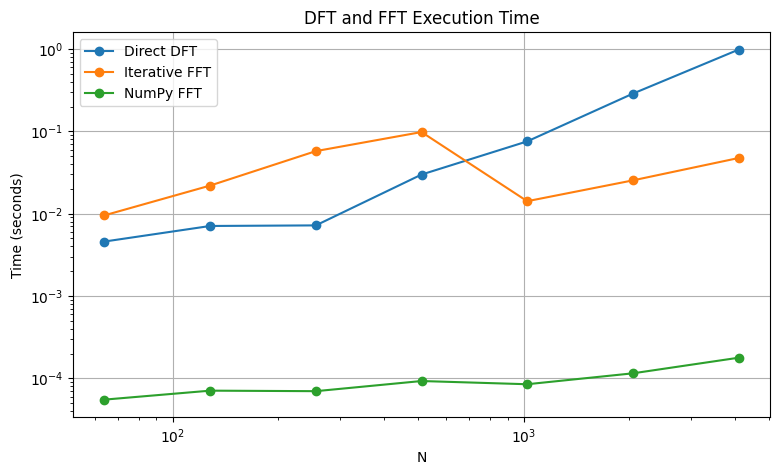

In [ ]:
N_values = [2**i for i in range(6, 13)]

dft_times = []
iter_times = []
numpy_times = []

for N in N_values:
    x = np.random.randn(N)

    start = time.perf_counter()
    dft_matrix(N) @ x
    dft_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    fft_iterative(x)
    iter_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    np.fft.fft(x)
    numpy_times.append(time.perf_counter() - start)

plt.figure(figsize=(9, 5))
plt.loglog(N_values, dft_times, 'o-', label='Direct DFT')
plt.loglog(N_values, iter_times, 'o-', label='Iterative FFT')
plt.loglog(N_values, numpy_times, 'o-', label='NumPy FFT')

plt.xlabel("N")
plt.ylabel("Time (seconds)")
plt.title("DFT and FFT Execution Time")
plt.legend()
plt.grid(True)
plt.show()

Task 5.5 — Zero-padding and the DTFT

/tmp/ipykernel_2242/3360284908.py:11: RuntimeWarning: invalid value encountered in divide
  dtft = np.abs(np.sin(2*omega) / np.sin(omega/2))


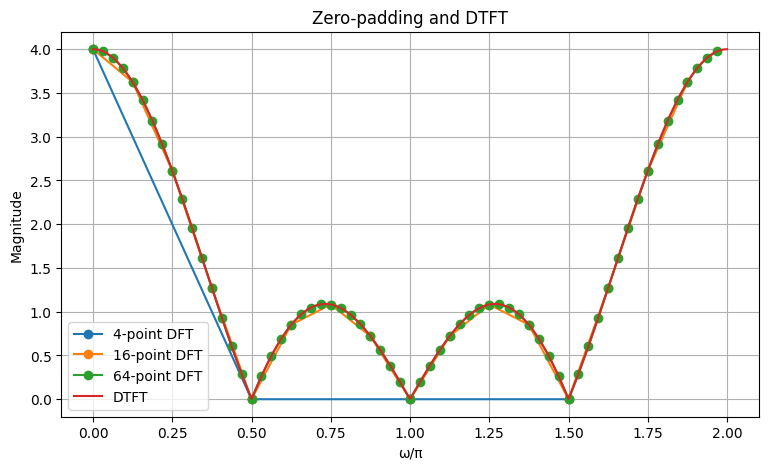

In [ ]:
x = np.array([1, 1, 1, 1])

plt.figure(figsize=(9, 5))

for N in [4, 16, 64]:
    X = np.fft.fft(x, N)
    w = np.arange(N) * 2 * np.pi / N
    plt.plot(w / np.pi, np.abs(X), 'o-', label=f'{N}-point DFT')

omega = np.linspace(0, 2*np.pi, 1000)
dtft = np.abs(np.sin(2*omega) / np.sin(omega/2))
dtft[np.isnan(dtft)] = 4

plt.plot(omega / np.pi, dtft, label='DTFT')

plt.xlabel('ω/π')
plt.ylabel('Magnitude')
plt.title('Zero-padding and DTFT')
plt.legend()
plt.grid()
plt.show()

Observation:

Zero-padding increases the number of frequency samples in the DFT, making the frequency spectrum smoother and providing better frequency resolution in the plotted spectrum. However, it does not change the original signal or the actual frequency content.

Task 5.6 — Fast Convolution

In [ ]:
rng = np.random.default_rng(0)

x = rng.standard_normal(10000)
h = np.ones(501) / 501

# Method (a): Direct convolution
start = time.perf_counter()
y_direct = np.convolve(x, h)
time_direct = time.perf_counter() - start

# Method (b): FFT convolution
L = len(x)
M = len(h)
N = 2**int(np.ceil(np.log2(L + M - 1)))

start = time.perf_counter()
y_fft = np.fft.ifft(
    np.fft.fft(x, N) * np.fft.fft(h, N)
).real[:L + M - 1]

time_fft = time.perf_counter() - start

print("Results match:", np.allclose(y_direct, y_fft))
print("Direct convolution time:", time_direct)
print("FFT convolution time:", time_fft)

Results match: True
Direct convolution time: 0.0035720909997962735
FFT convolution time: 0.002557159999923897


Observation

The FFT-based convolution produced results that matched direct convolution. It was slightly faster than `np.convolve` for this experiment. FFT convolution can be more efficient for long signals and filters.

In [ ]:
x1 = np.array([2, 1.5, 1, 0.5])
h1 = np.array([1, 0, 1, 0])

circular = np.fft.ifft(
    np.fft.fft(x1) * np.fft.fft(h1)
).real

print(np.round(circular, 4))

[3. 2. 3. 2.]


**Analysis Questions**

**1. Speed-up of FFT over direct DFT at N = 4096**

The speed-up is calculated by dividing the direct DFT execution time by the iterative FFT execution time:

Speed-up = Direct DFT time / Iterative FFT time.

The iterative FFT is faster because it requires approximately O(N log₂N) operations, while the direct DFT requires O(N²) operations. `np.fft.fft` is even faster because it uses highly optimized numerical libraries and efficient implementation techniques.

**2. Why is bit reversal needed in the DIT algorithm?**

Bit reversal rearranges the input samples into the correct order before performing the FFT stages. This allows the butterfly operations to combine the correct samples at each stage and makes the iterative DIT algorithm work correctly.

**3. Why must both sequences be zero-padded to at least L + M − 1?**

Zero-padding ensures that the FFT-based circular convolution produces the same result as linear convolution. Without sufficient padding, circular convolution causes time-domain overlap (wraparound), which changes the result.

**4. Number of complex multiplications per second in a 2048-point FFT**

For a radix-2 FFT:

Number of complex multiplications = (N/2) log₂N

For N = 2048:

= (2048/2) × 11

= 11,264 complex multiplications per FFT.

The FFT is performed every 66.7 μs:

Number of FFTs per second = 1 / (66.7 × 10⁻⁶)

≈ 14,992.5 FFTs per second.

Therefore:

Complex multiplications per second = 11,264 × 14,992.5

≈ **168,876,000 complex multiplications per second.**

Approximately **168.9 million complex multiplications per second**.